# Route Optimization using GA, ACO, and Hybrid GA-ACO

**Libraries**

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from collections import defaultdict
import itertools
import time
import warnings
warnings.filterwarnings('ignore')

In [2]:
data = {
    "location_id": list(range(30)),
    "x": [51, 92, 14, 71, 60, 20, 82, 86, 74, 74,
          87, 99, 23, 2, 21, 52, 1, 87, 29, 37,
          1, 63, 59, 20, 32, 75, 57, 21, 88, 48],
    "y": [90, 58, 41, 91, 59, 79, 14, 61, 61, 46,
          61, 50, 54, 63, 2, 50, 6, 20, 72, 38,
          17, 3, 88, 59, 13, 8, 89, 52, 1, 83]
}

# Create DataFrame
df = pd.DataFrame(data)

# Save to CSV
df.to_csv("route_dataset.csv", index=False)

**Load Dataset**

In [3]:
# Load dataset
df = pd.read_csv('route_dataset.csv')
locations = df[['x', 'y']].values
n_locations = len(locations)

**Calculate distance matrix (Euclidean)**

In [4]:
dist_matrix = np.zeros((n_locations, n_locations))
for i in range(n_locations):
    for j in range(n_locations):
        dist_matrix[i][j] = np.linalg.norm(locations[i] - locations[j])

In [5]:
def total_distance(route, dist_matrix):
    """Calculate total distance of a route (0-indexed list of nodes)"""
    dist = 0
    for i in range(len(route)-1):
        dist += dist_matrix[route[i]][route[i+1]]
    dist += dist_matrix[route[-1]][route[0]]  # return to start
    return dist

In [6]:
def plot_route(route, locations, title):
    plt.figure(figsize=(8,6))
    route_coords = locations[route]
    plt.plot(route_coords[:,0], route_coords[:,1], 'o-', linewidth=1, markersize=4)
    plt.plot(route_coords[0,0], route_coords[0,1], 'ro', markersize=8, label='Start')
    plt.title(title)
    plt.xlabel('X')
    plt.ylabel('Y')
    plt.legend()
    plt.grid(True)
    plt.show()

**Genetic Algorithm**

In [7]:
class GeneticAlgorithm:
    def __init__(self, dist_matrix, pop_size=100, generations=500, mutation_rate=0.02, elite_size=10):
        self.dist_matrix = dist_matrix
        self.n_cities = len(dist_matrix)
        self.pop_size = pop_size
        self.generations = generations
        self.mutation_rate = mutation_rate
        self.elite_size = elite_size
        
    def create_individual(self):
        return list(np.random.permutation(self.n_cities))
    
    def create_population(self):
        return [self.create_individual() for _ in range(self.pop_size)]
    
    def fitness(self, route):
        return 1.0 / total_distance(route, self.dist_matrix)
    
    def select_parent(self, population, fitnesses):
        # Tournament selection
        idx1, idx2 = np.random.choice(len(population), 2, replace=False)
        return population[idx1] if fitnesses[idx1] > fitnesses[idx2] else population[idx2]
    
    def crossover(self, parent1, parent2):
        # Ordered crossover (OX)
        start, end = sorted(np.random.choice(self.n_cities, 2, replace=False))
        child = [-1]*self.n_cities
        child[start:end] = parent1[start:end]
        fill_idx = 0
        for gene in parent2:
            if gene not in child:
                while child[fill_idx] != -1:
                    fill_idx += 1
                child[fill_idx] = gene
        return child
    
    def mutate(self, route):
        if np.random.random() < self.mutation_rate:
            i, j = np.random.choice(self.n_cities, 2, replace=False)
            route[i], route[j] = route[j], route[i]
        return route
    
    def evolve(self, population):
        fitnesses = [self.fitness(ind) for ind in population]
        # Elitism
        elites_idx = np.argsort(fitnesses)[-self.elite_size:]
        new_population = [population[i][:] for i in elites_idx]
        
        while len(new_population) < self.pop_size:
            parent1 = self.select_parent(population, fitnesses)
            parent2 = self.select_parent(population, fitnesses)
            child = self.crossover(parent1, parent2)
            child = self.mutate(child)
            new_population.append(child)
        return new_population
    
    def run(self, verbose=False):
        population = self.create_population()
        best_distances = []
        avg_distances = []
        times = []
        start_time = time.time()
        
        for gen in range(self.generations):
            population = self.evolve(population)
            fitnesses = [self.fitness(ind) for ind in population]
            best_idx = np.argmax(fitnesses)
            best_route = population[best_idx]
            best_dist = total_distance(best_route, self.dist_matrix)
            avg_dist = np.mean([total_distance(ind, self.dist_matrix) for ind in population])
            best_distances.append(best_dist)
            avg_distances.append(avg_dist)
            times.append(time.time() - start_time)
            if verbose and gen % 50 == 0:
                print(f"Gen {gen}: Best Dist = {best_dist:.2f}, Avg Dist = {avg_dist:.2f}")
        
        final_best_idx = np.argmax([self.fitness(ind) for ind in population])
        final_best_route = population[final_best_idx]
        final_best_dist = total_distance(final_best_route, self.dist_matrix)
        
        return {
            'best_route': final_best_route,
            'best_distance': final_best_dist,
            'convergence': best_distances,
            'avg_convergence': avg_distances,
            'times': times
        }

**Ant Colony Optimization**

In [8]:
class AntColonyOptimization:
    def __init__(self, dist_matrix, n_ants=50, n_iterations=500, alpha=1.0, beta=2.0, evaporation=0.5, Q=100):
        self.dist_matrix = dist_matrix
        self.n_cities = len(dist_matrix)
        self.n_ants = n_ants
        self.n_iterations = n_iterations
        self.alpha = alpha  # pheromone importance
        self.beta = beta    # distance importance
        self.evaporation = evaporation
        self.Q = Q
        self.pheromone = np.ones((self.n_cities, self.n_cities)) / self.n_cities
        
    def _distance(self, city1, city2):
        return self.dist_matrix[city1][city2]
    
    def _select_next_city(self, current, unvisited):
        probabilities = []
        for city in unvisited:
            pheromone = self.pheromone[current][city] ** self.alpha
            visibility = (1.0 / self._distance(current, city)) ** self.beta
            probabilities.append(pheromone * visibility)
        probabilities = np.array(probabilities)
        if np.sum(probabilities) == 0:
            return np.random.choice(unvisited)
        probabilities /= np.sum(probabilities)
        return np.random.choice(unvisited, p=probabilities)
    
    def _construct_route(self, start_city):
        route = [start_city]
        unvisited = set(range(self.n_cities)) - {start_city}
        while unvisited:
            next_city = self._select_next_city(route[-1], list(unvisited))
            route.append(next_city)
            unvisited.remove(next_city)
        return route
    
    def run(self, verbose=False):
        best_distance_overall = float('inf')
        best_route_overall = None
        best_distances_per_iter = []
        avg_distances_per_iter = []
        times = []
        start_time = time.time()
        
        for it in range(self.n_iterations):
            all_routes = []
            all_distances = []
            for ant in range(self.n_ants):
                start = np.random.randint(self.n_cities)
                route = self._construct_route(start)
                dist = total_distance(route, self.dist_matrix)
                all_routes.append(route)
                all_distances.append(dist)
                if dist < best_distance_overall:
                    best_distance_overall = dist
                    best_route_overall = route.copy()
            
            # Update pheromones
            self.pheromone *= (1 - self.evaporation)
            for route, dist in zip(all_routes, all_distances):
                contribution = self.Q / dist
                for i in range(len(route)-1):
                    self.pheromone[route[i]][route[i+1]] += contribution
                    self.pheromone[route[i+1]][route[i]] += contribution
                self.pheromone[route[-1]][route[0]] += contribution
                self.pheromone[route[0]][route[-1]] += contribution
            
            best_distances_per_iter.append(best_distance_overall)
            avg_distances_per_iter.append(np.mean(all_distances))
            times.append(time.time() - start_time)
            if verbose and it % 50 == 0:
                print(f"Iter {it}: Best Dist = {best_distance_overall:.2f}, Avg Dist = {np.mean(all_distances):.2f}")
        
        return {
            'best_route': best_route_overall,
            'best_distance': best_distance_overall,
            'convergence': best_distances_per_iter,
            'avg_convergence': avg_distances_per_iter,
            'times': times
        }

**Hybrid GA+ACO**

In [9]:
class HybridGeneticACO:
    def __init__(self, dist_matrix, pop_size=80, generations=300, mutation_rate=0.02, elite_size=8, 
                 n_ants=30, alpha=1.0, beta=2.0, evaporation=0.5, hybrid_interval=10):
        self.dist_matrix = dist_matrix
        self.n_cities = len(dist_matrix)
        self.pop_size = pop_size
        self.generations = generations
        self.mutation_rate = mutation_rate
        self.elite_size = elite_size
        self.n_ants = n_ants
        self.alpha = alpha
        self.beta = beta
        self.evaporation = evaporation
        self.hybrid_interval = hybrid_interval  # Run ACO every N generations
        
    def create_individual(self):
        return list(np.random.permutation(self.n_cities))
    
    def create_population(self):
        return [self.create_individual() for _ in range(self.pop_size)]
    
    def fitness(self, route):
        return 1.0 / total_distance(route, self.dist_matrix)
    
    def select_parent(self, population, fitnesses):
        idx1, idx2 = np.random.choice(len(population), 2, replace=False)
        return population[idx1] if fitnesses[idx1] > fitnesses[idx2] else population[idx2]
    
    def crossover(self, parent1, parent2):
        start, end = sorted(np.random.choice(self.n_cities, 2, replace=False))
        child = [-1]*self.n_cities
        child[start:end] = parent1[start:end]
        fill_idx = 0
        for gene in parent2:
            if gene not in child:
                while child[fill_idx] != -1:
                    fill_idx += 1
                child[fill_idx] = gene
        return child
    
    def mutate(self, route):
        if np.random.random() < self.mutation_rate:
            i, j = np.random.choice(self.n_cities, 2, replace=False)
            route[i], route[j] = route[j], route[i]
        return route
    
    def aco_improvement(self, population):
        # Use ACO to generate new routes and replace worst in population
        pheromone = np.ones((self.n_cities, self.n_cities)) / self.n_cities
        # Initialize pheromone from population routes
        for route in population[:self.pop_size//2]:
            dist = total_distance(route, self.dist_matrix)
            contribution = 100 / dist
            for i in range(len(route)-1):
                pheromone[route[i]][route[i+1]] += contribution
            pheromone[route[-1]][route[0]] += contribution
        
        def select_next(current, unvisited, pheromone):
            probs = []
            for city in unvisited:
                prob = (pheromone[current][city] ** self.alpha) * ((1.0/self.dist_matrix[current][city]) ** self.beta)
                probs.append(prob)
            probs = np.array(probs)
            if np.sum(probs) == 0:
                return np.random.choice(list(unvisited))
            probs /= np.sum(probs)
            return np.random.choice(list(unvisited), p=probs)
        
        new_routes = []
        for _ in range(self.n_ants):
            start = np.random.randint(self.n_cities)
            route = [start]
            unvisited = set(range(self.n_cities)) - {start}
            while unvisited:
                nxt = select_next(route[-1], unvisited, pheromone)
                route.append(nxt)
                unvisited.remove(nxt)
            new_routes.append(route)
        
        # Replace worst individuals
        fitnesses = [self.fitness(r) for r in population]
        sorted_idx = np.argsort(fitnesses)
        for i, route in enumerate(new_routes[:self.elite_size]):
            population[sorted_idx[i]] = route
        return population
    
    def run(self, verbose=False):
        population = self.create_population()
        best_distances = []
        avg_distances = []
        times = []
        start_time = time.time()
        
        for gen in range(self.generations):
            # Standard GA evolution
            fitnesses = [self.fitness(ind) for ind in population]
            elites_idx = np.argsort(fitnesses)[-self.elite_size:]
            new_population = [population[i][:] for i in elites_idx]
            
            while len(new_population) < self.pop_size:
                parent1 = self.select_parent(population, fitnesses)
                parent2 = self.select_parent(population, fitnesses)
                child = self.crossover(parent1, parent2)
                child = self.mutate(child)
                new_population.append(child)
            population = new_population
            
            # Hybrid step: apply ACO improvement periodically
            if gen % self.hybrid_interval == 0 and gen > 0:
                population = self.aco_improvement(population)
            
            fitnesses = [self.fitness(ind) for ind in population]
            best_idx = np.argmax(fitnesses)
            best_route = population[best_idx]
            best_dist = total_distance(best_route, self.dist_matrix)
            avg_dist = np.mean([total_distance(ind, self.dist_matrix) for ind in population])
            best_distances.append(best_dist)
            avg_distances.append(avg_dist)
            times.append(time.time() - start_time)
            if verbose and gen % 50 == 0:
                print(f"Gen {gen}: Best Dist = {best_dist:.2f}, Avg Dist = {avg_dist:.2f}")
        
        final_best_idx = np.argmax([self.fitness(ind) for ind in population])
        final_best_route = population[final_best_idx]
        final_best_dist = total_distance(final_best_route, self.dist_matrix)
        
        return {
            'best_route': final_best_route,
            'best_distance': final_best_dist,
            'convergence': best_distances,
            'avg_convergence': avg_distances,
            'times': times
        }

**Calling Algorithm CLasses**

In [10]:
print("Running Genetic Algorithm...")
ga = GeneticAlgorithm(dist_matrix, pop_size=100, generations=500, mutation_rate=0.02)
ga_results = ga.run(verbose=True)

Running Genetic Algorithm...
Gen 0: Best Dist = 1378.27, Avg Dist = 1599.31
Gen 50: Best Dist = 609.18, Avg Dist = 614.21
Gen 100: Best Dist = 601.95, Avg Dist = 602.18
Gen 150: Best Dist = 601.95, Avg Dist = 606.42
Gen 200: Best Dist = 571.46, Avg Dist = 575.14
Gen 250: Best Dist = 559.89, Avg Dist = 566.79
Gen 300: Best Dist = 552.22, Avg Dist = 558.14
Gen 350: Best Dist = 543.01, Avg Dist = 545.94
Gen 400: Best Dist = 543.01, Avg Dist = 547.84
Gen 450: Best Dist = 543.01, Avg Dist = 544.09


In [11]:
print("\nRunning Ant Colony Optimization...")
aco = AntColonyOptimization(dist_matrix, n_ants=50, n_iterations=500, alpha=1.0, beta=2.0)
aco_results = aco.run(verbose=True)


Running Ant Colony Optimization...
Iter 0: Best Dist = 681.79, Avg Dist = 901.65
Iter 50: Best Dist = 471.42, Avg Dist = 573.26
Iter 100: Best Dist = 469.29, Avg Dist = 574.53
Iter 150: Best Dist = 469.29, Avg Dist = 584.31
Iter 200: Best Dist = 469.29, Avg Dist = 582.69
Iter 250: Best Dist = 469.28, Avg Dist = 569.10
Iter 300: Best Dist = 469.28, Avg Dist = 580.43
Iter 350: Best Dist = 469.28, Avg Dist = 581.91
Iter 400: Best Dist = 462.31, Avg Dist = 582.10
Iter 450: Best Dist = 462.31, Avg Dist = 583.20


In [12]:
print("\nRunning Hybrid GA-ACO...")
hybrid = HybridGeneticACO(dist_matrix, pop_size=80, generations=500, mutation_rate=0.02, 
                          n_ants=30, hybrid_interval=10)
hybrid_results = hybrid.run(verbose=True)


Running Hybrid GA-ACO...
Gen 0: Best Dist = 1369.79, Avg Dist = 1595.36
Gen 50: Best Dist = 589.18, Avg Dist = 746.15
Gen 100: Best Dist = 577.16, Avg Dist = 646.79
Gen 150: Best Dist = 500.75, Avg Dist = 539.57
Gen 200: Best Dist = 490.04, Avg Dist = 537.25
Gen 250: Best Dist = 490.04, Avg Dist = 492.05
Gen 300: Best Dist = 490.04, Avg Dist = 492.65
Gen 350: Best Dist = 490.04, Avg Dist = 494.70
Gen 400: Best Dist = 490.04, Avg Dist = 494.63
Gen 450: Best Dist = 490.04, Avg Dist = 495.69


**Metrics**

In [13]:
def compute_metrics(results_dict, algo_name, convergence_list, times_list):
    final_dist = results_dict['best_distance']
    # Time to reach 95% of final distance
    target = 0.95 * final_dist
    convergence = convergence_list
    gen_to_target = 0
    for i, dist in enumerate(convergence):
        if dist <= target:
            gen_to_target = i
            break
    total_time = times_list[-1] if times_list else 0
    return {
        'Algorithm': algo_name,
        'Final Distance': final_dist,
        'Gen/Iter to 95%': gen_to_target,
        'Total Time (s)': total_time
    }

In [14]:
ga_metrics = compute_metrics(ga_results, 'Genetic Algorithm', ga_results['convergence'], ga_results['times'])
aco_metrics = compute_metrics(aco_results, 'Ant Colony Optimization', aco_results['convergence'], aco_results['times'])
hybrid_metrics = compute_metrics(hybrid_results, 'Hybrid GA-ACO', hybrid_results['convergence'], hybrid_results['times'])

In [15]:
metrics_df = pd.DataFrame([ga_metrics, aco_metrics, hybrid_metrics])
metrics_df

,Algorithm,Final Distance,Gen/Iter to 95%,Total Time (s)
0,Genetic Algorithm,543.010361,0,6.681528
1,Ant Colony Optimization,462.309128,0,40.990959
2,Hybrid GA-ACO,490.043064,0,6.576143


**Convergence Curves**

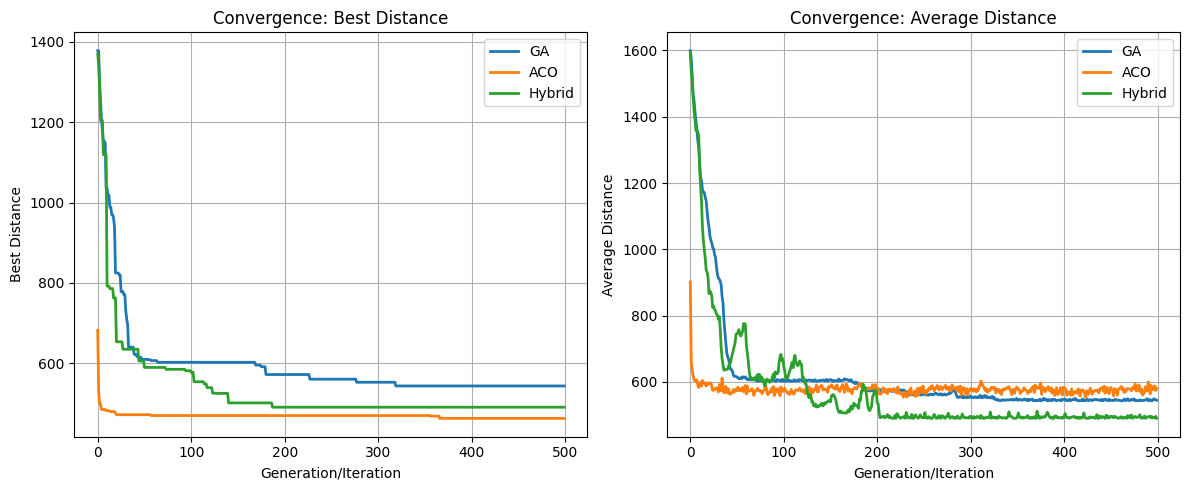

In [16]:
plt.figure(figsize=(12,5))

plt.subplot(1,2,1)
plt.plot(ga_results['convergence'], label='GA', linewidth=2)
plt.plot(aco_results['convergence'], label='ACO', linewidth=2)
plt.plot(hybrid_results['convergence'], label='Hybrid', linewidth=2)
plt.xlabel('Generation/Iteration')
plt.ylabel('Best Distance')
plt.title('Convergence: Best Distance')
plt.legend()
plt.grid(True)

plt.subplot(1,2,2)
plt.plot(ga_results['avg_convergence'], label='GA', linewidth=2)
plt.plot(aco_results['avg_convergence'], label='ACO', linewidth=2)
plt.plot(hybrid_results['avg_convergence'], label='Hybrid', linewidth=2)
plt.xlabel('Generation/Iteration')
plt.ylabel('Average Distance')
plt.title('Convergence: Average Distance')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

**Best Routes for Each Algorithm**

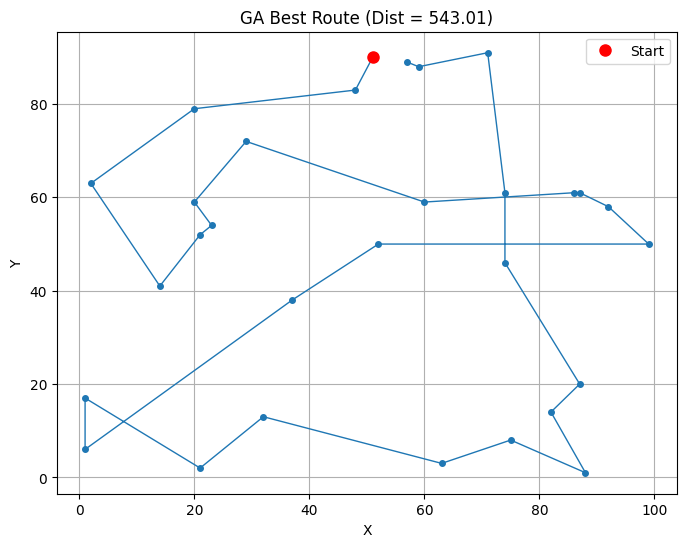

In [17]:
plot_route(ga_results['best_route'], locations, f"GA Best Route (Dist = {ga_results['best_distance']:.2f})")

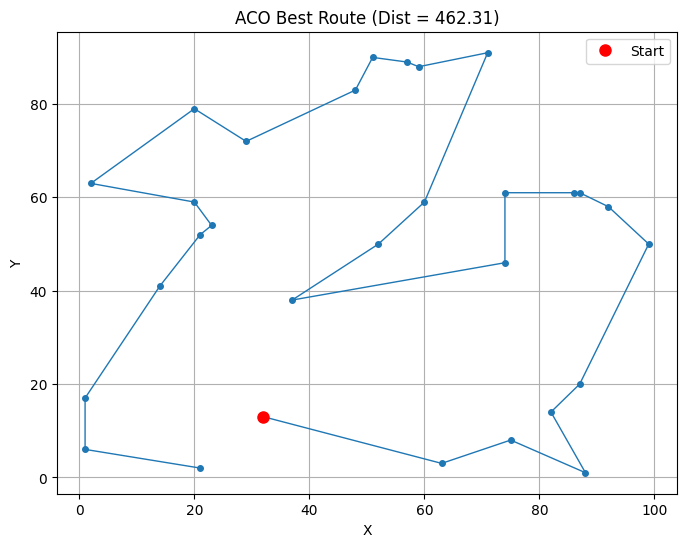

In [18]:
plot_route(aco_results['best_route'], locations, f"ACO Best Route (Dist = {aco_results['best_distance']:.2f})")

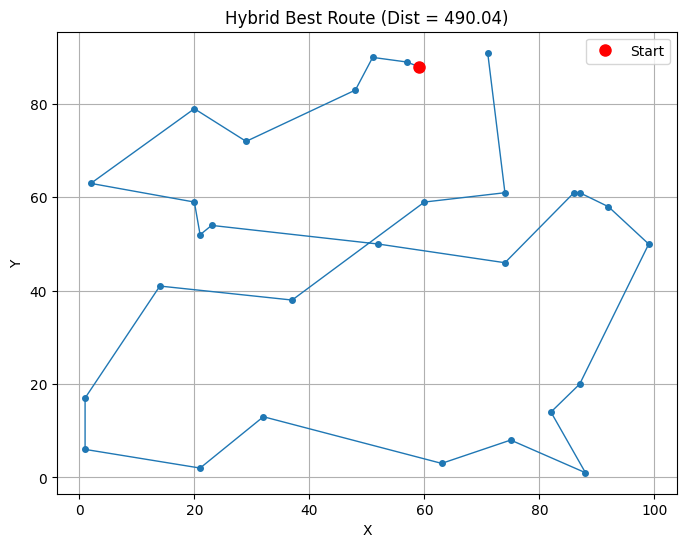

In [19]:
plot_route(hybrid_results['best_route'], locations, f"Hybrid Best Route (Dist = {hybrid_results['best_distance']:.2f})")

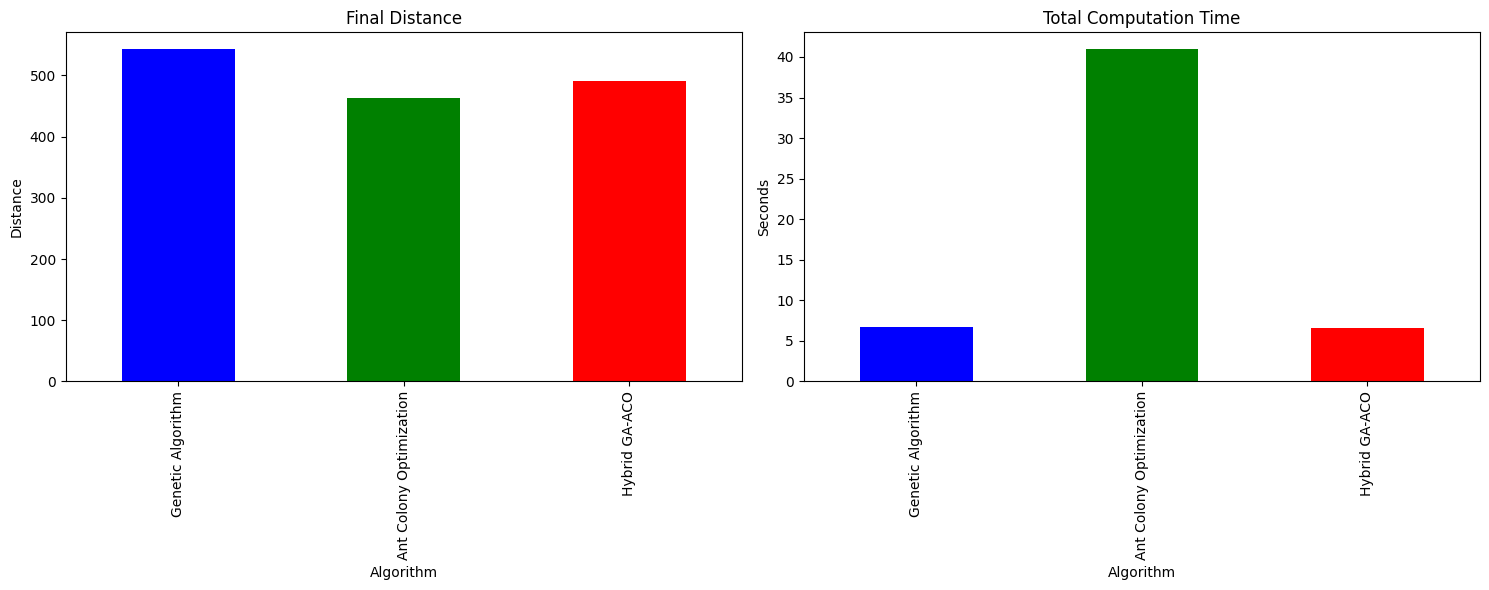

In [20]:
fig, ax = plt.subplots(1,2, figsize=(15,6))
metrics_plot = metrics_df.set_index('Algorithm')
metrics_plot['Final Distance'].plot(kind='bar', ax=ax[0], color=['blue','green','red'])
ax[0].set_title('Final Distance')
ax[0].set_ylabel('Distance')
metrics_plot['Total Time (s)'].plot(kind='bar', ax=ax[1], color=['blue','green','red'])
ax[1].set_title('Total Computation Time')
ax[1].set_ylabel('Seconds')
plt.tight_layout()
plt.show()